# Detection criteria and lightcurve quality analysis

This notebook analyzes outputs produced by `scripts/run_detection_criteria_sweep.sh`. It does not run simulations.

In [1]:
from pathlib import Path
import json
import re
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('results/detection_criteria_sweep')
QUALITY = ROOT / 'lightcurve_quality.csv'
if not QUALITY.exists():
    raise FileNotFoundError(f'Run lightcurve_quality_analysis.py first: {QUALITY}')
quality = pd.read_csv(QUALITY)
quality.head()

,file,source_index,z,t_exp,n_positive,n_non_detections,n_bands,bands,duplicate_positive_times,positive_span_days,...,positive_span_exceeds_14_days,all_observation_span_exceeds_14_days,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,band_counts
0,results/detection_criteria_sweep/snr4_snr22_nd...,0,0.02857,60154.698,9,100,2,g;r,0,88.89029,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 2, ""r"": 7}"
1,results/detection_criteria_sweep/snr4_snr22_nd...,1,0.06014,58525.968,1,435,1,g,0,0.00000,...,False,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1}"
2,results/detection_criteria_sweep/snr4_snr22_nd...,2,0.04193,59464.779,11,220,2,g;r,0,49.94175,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 7, ""r"": 4}"
3,results/detection_criteria_sweep/snr4_snr22_nd...,3,0.02556,60691.361,3,74,2,g;r,0,22.00574,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 1, ""r"": 2}"
4,results/detection_criteria_sweep/snr4_snr22_nd...,4,0.03360,60263.142,12,109,2,g;r,0,62.72165,...,True,True,4.0,2.0,2,1,12.0,0.3,0.0,"{""g"": 6, ""r"": 6}"


## Lightcurve quality

The configured span is the detector's qualifying window. The all-observation span is reported separately because stored non-detections may extend beyond that window.

In [2]:
numeric = [
    'n_positive', 'n_non_detections', 'n_bands', 'duplicate_positive_times',
    'positive_span_days', 'all_observation_span_days', 'max_positive_gap_days',
    'min_positive_gap_days', 'configured_max_timespan_days'
]
quality[numeric] = quality[numeric].apply(pd.to_numeric, errors='coerce')
quality['positive_span_exceeds_configured_days'] = quality['positive_span_exceeds_configured_days'].astype(bool)
quality['all_observation_span_exceeds_configured_days'] = quality['all_observation_span_exceeds_configured_days'].astype(bool)
quality[numeric].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).T

,count,mean,std,min,50%,90%,95%,99%,max
n_positive,177919.0,7.917277,9.159565,1.00000,5.00000,18.000000,25.000000,44.000000,228.00000
n_non_detections,177919.0,163.362463,131.578017,0.00000,129.00000,324.000000,410.000000,646.000000,1655.00000
n_bands,177919.0,1.722548,0.612274,1.00000,2.00000,2.000000,3.000000,3.000000,3.00000
duplicate_positive_times,177919.0,0.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.00000
positive_span_days,177919.0,44.470539,34.319166,0.00000,44.90143,90.872240,95.809444,100.818493,104.84413
all_observation_span_days,177919.0,114.709732,20.735751,0.98089,120.35103,132.820622,133.830230,134.897165,138.94900
max_positive_gap_days,177919.0,21.279027,18.117768,0.00000,19.98867,45.931228,55.892464,79.874883,104.72227
min_positive_gap_days,177919.0,3.646015,10.634229,0.00000,0.02249,8.985892,23.970953,58.860130,104.72227
configured_max_timespan_days,177919.0,17.323720,5.149533,3.00000,21.00000,21.000000,21.000000,21.000000,21.00000


In [3]:
quality_summary = (
    quality.groupby([
        'criteria_snr_threshold', 'criteria_snr_threshold_secondary',
        'criteria_min_detections', 'criteria_min_detections_primary',
        'configured_max_timespan_days', 'criteria_min_time_separation_hours',
        'criteria_min_fade_rate', 'criteria_min_galactic_lat',
    ], dropna=False)
    .agg(
        sources=('source_index', 'size'),
        median_positive_span_days=('positive_span_days', 'median'),
        p95_positive_span_days=('positive_span_days', lambda values: values.quantile(0.95)),
        median_max_gap_days=('max_positive_gap_days', 'median'),
        positive_span_violations=('positive_span_exceeds_configured_days', 'sum'),
        all_span_violations=('all_observation_span_exceeds_configured_days', 'sum'),
        duplicate_time_sources=('duplicate_positive_times', lambda values: (values > 0).sum()),
    )
    .reset_index()
)
quality_summary.sort_values('positive_span_violations', ascending=False).head(20)

,criteria_snr_threshold,criteria_snr_threshold_secondary,criteria_min_detections,criteria_min_detections_primary,configured_max_timespan_days,criteria_min_time_separation_hours,criteria_min_fade_rate,criteria_min_galactic_lat,sources,median_positive_span_days,p95_positive_span_days,median_max_gap_days,positive_span_violations,all_span_violations,duplicate_time_sources
603,4.0,4.0,2,1,21.0,12.0,0.0,0.0,766,50.927695,95.475082,20.024430,537,765,0
644,4.0,4.0,2,2,21.0,3.0,0.0,0.0,736,48.899405,95.886857,20.032085,521,735,0
650,4.0,4.0,2,2,21.0,12.0,0.0,0.0,740,44.004320,94.886765,20.866120,505,740,0
597,4.0,4.0,2,1,21.0,3.0,0.0,0.0,712,47.464430,95.885674,19.827540,481,711,0
832,4.0,4.0,4,2,21.0,3.0,0.0,0.0,656,52.405670,94.850733,19.931410,476,656,0
744,4.0,4.0,3,2,21.0,12.0,0.0,0.0,668,44.924300,95.044815,19.985325,472,668,0
697,4.0,4.0,3,1,21.0,12.0,0.0,0.0,689,39.942340,94.570946,18.880410,460,689,0
738,4.0,4.0,3,2,21.0,3.0,0.0,0.0,678,44.998965,95.836735,18.966300,459,678,0
1579,5.0,4.0,3,2,21.0,12.0,0.0,0.0,645,44.991020,95.610978,19.837600,442,644,0
1439,5.0,4.0,2,1,21.0,12.0,0.0,0.0,671,41.984630,95.983205,20.033100,438,671,0


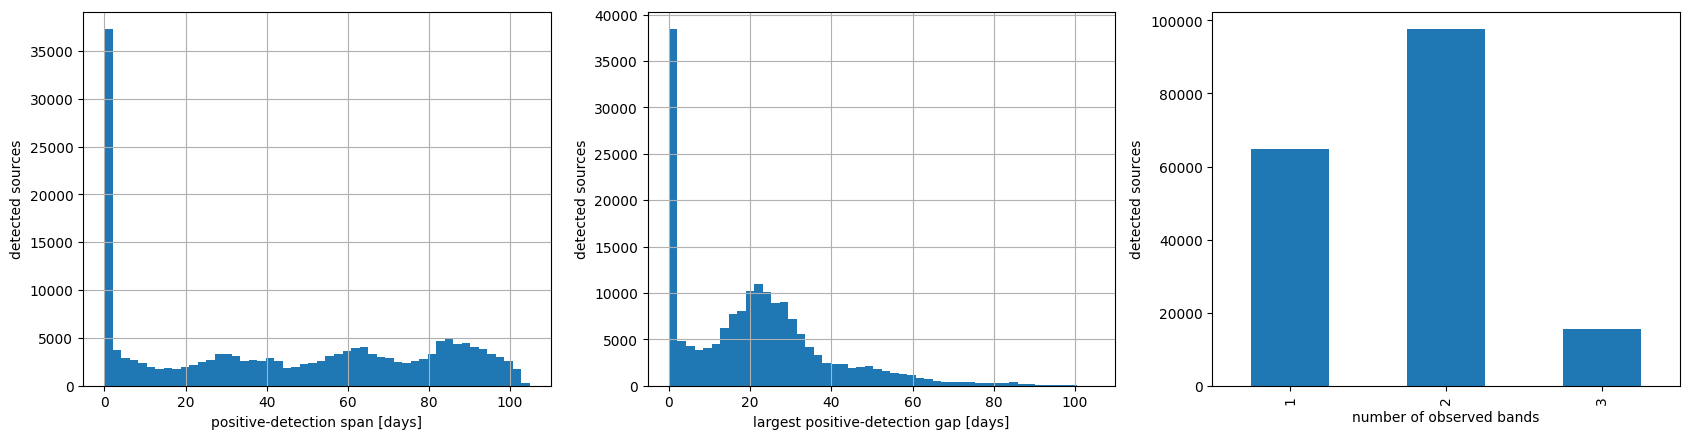

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
quality['positive_span_days'].hist(ax=axes[0], bins=50)
axes[0].set(xlabel='positive-detection span [days]', ylabel='detected sources')
quality['max_positive_gap_days'].hist(ax=axes[1], bins=50)
axes[1].set(xlabel='largest positive-detection gap [days]', ylabel='detected sources')
quality['n_bands'].value_counts().sort_index().plot.bar(ax=axes[2])
axes[2].set(xlabel='number of observed bands', ylabel='detected sources')
fig.tight_layout()

## Rate-limit comparison

Each simulation result is paired with its metadata sidecar. The rate table below is built directly from the serialized `rate_summaries`; no rates are recomputed from the lightcurve audit.

In [5]:
rate_rows = []
for result_path in sorted(ROOT.glob('**/*.json')):
    if result_path.name.endswith('.metadata.json'):
        continue
    with result_path.open() as handle:
        result = json.load(handle)
    metadata_path = Path(f'{result_path}.metadata.json')
    metadata = json.loads(metadata_path.read_text()) if metadata_path.exists() else {}
    criteria = metadata.get('detection_criteria', {})
    for summary in result.get('rate_summaries', []):
        row = dict(summary)
        row.update({
            'file': str(result_path),
            'snr_threshold': criteria.get('snr_threshold'),
            'snr_threshold_secondary': criteria.get('snr_threshold_secondary'),
            'min_detections': criteria.get('min_detections'),
            'min_detections_primary': criteria.get('min_detections_primary'),
            'max_timespan_days': criteria.get('max_timespan_days'),
            'min_time_separation_hours': criteria.get('min_time_separation_hours'),
            'min_fade_rate': criteria.get('min_fade_rate'),
            'min_galactic_lat': criteria.get('min_galactic_lat'),
        })
        rate_rows.append(row)
rates = pd.DataFrame(rate_rows)
if rates.empty:
    raise ValueError(f'No rate summaries found under {ROOT}')
rates['rate_95_zero_events'] = -__import__('numpy').log(0.05) / pd.to_numeric(rates['effective_vt_gpc3_yr'])
rates.sort_values(['snr_threshold', 'snr_threshold_secondary', 'min_detections', 'max_timespan_days']).head(20)

,transient_type,volumetric_rate,detections_per_year,detections_total,overall_efficiency,n_simulated,n_detected,z_max,survey_omega_sr,survey_duration_years,...,file,snr_threshold,snr_threshold_secondary,min_detections,min_detections_primary,max_timespan_days,min_time_separation_hours,min_fade_rate,min_galactic_lat,rate_95_zero_events
24,Kilonova,1000.0,0.05466,0.43756,0.00005,100000,5,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,12.0,0.3,0.0,6.808482e+03
25,Kilonova,1000.0,0.01116,0.08937,0.00001,100000,1,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,12.0,0.3,15.0,3.328591e+04
26,Kilonova,1000.0,0.02227,0.17825,0.00002,100000,2,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,12.0,0.6,0.0,1.664296e+04
27,Kilonova,1000.0,0.04200,0.33621,0.00004,100000,4,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,12.0,0.6,15.0,8.810977e+03
28,Kilonova,1000.0,0.30762,2.46268,0.00029,100000,29,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,12.0,0.0,0.0,1.217777e+03
29,Kilonova,1000.0,0.21088,1.68822,0.00020,100000,20,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,12.0,0.0,15.0,1.772623e+03
30,Kilonova,1000.0,0.06513,0.52141,0.00006,100000,6,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,3.0,0.3,0.0,5.761024e+03
31,Kilonova,1000.0,0.01027,0.08223,0.00001,100000,1,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,3.0,0.3,15.0,3.744665e+04
32,Kilonova,1000.0,0.05791,0.46359,0.00006,100000,6,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,3.0,0.6,0.0,6.512461e+03
33,Kilonova,1000.0,0.00000,0.00000,0.00000,100000,0,0.15,8.21881,8.00571,...,results/detection_criteria_sweep/snr4_snr22_nd...,4.0,2.0,2,1,3.0,3.0,0.6,15.0,inf


In [6]:
rate_summary = (
    rates.groupby([
        'snr_threshold', 'snr_threshold_secondary', 'min_detections',
        'min_detections_primary', 'max_timespan_days',
        'min_time_separation_hours', 'min_fade_rate', 'min_galactic_lat',
    ], dropna=False)
    .agg(
        runs=('file', 'nunique'),
        detected=('n_detected', 'mean'),
        efficiency=('overall_efficiency', 'mean'),
        vt_eff=('effective_vt_gpc3_yr', 'mean'),
        rate_95=('rate_95_zero_events', 'mean'),
    )
    .reset_index()
)
rate_summary.sort_values('rate_95')

,snr_threshold,snr_threshold_secondary,min_detections,min_detections_primary,max_timespan_days,min_time_separation_hours,min_fade_rate,min_galactic_lat,runs,detected,efficiency,vt_eff,rate_95
1482,5.0,4.0,2,1,21.0,12.0,0.0,0.0,1,1042.0,0.01042,0.08799,34.046281
618,4.0,4.0,2,1,21.0,12.0,0.0,0.0,1,1027.0,0.01027,0.08551,35.033707
660,4.0,4.0,2,2,21.0,3.0,0.0,0.0,1,997.0,0.00997,0.08445,35.473443
1476,5.0,4.0,2,1,21.0,3.0,0.0,0.0,1,998.0,0.00998,0.08443,35.481846
666,4.0,4.0,2,2,21.0,12.0,0.0,0.0,1,981.0,0.00981,0.08315,36.028049
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1112,5.0,2.0,4,2,3.0,12.0,0.3,0.0,1,0.0,0.00000,0.00000,inf
1781,6.0,2.0,2,2,3.0,3.0,0.6,15.0,1,0.0,0.00000,0.00000,inf
2067,6.0,3.0,2,2,3.0,3.0,0.3,15.0,1,0.0,0.00000,0.00000,inf
53,4.0,2.0,2,2,3.0,3.0,0.6,15.0,1,0.0,0.00000,0.00000,inf


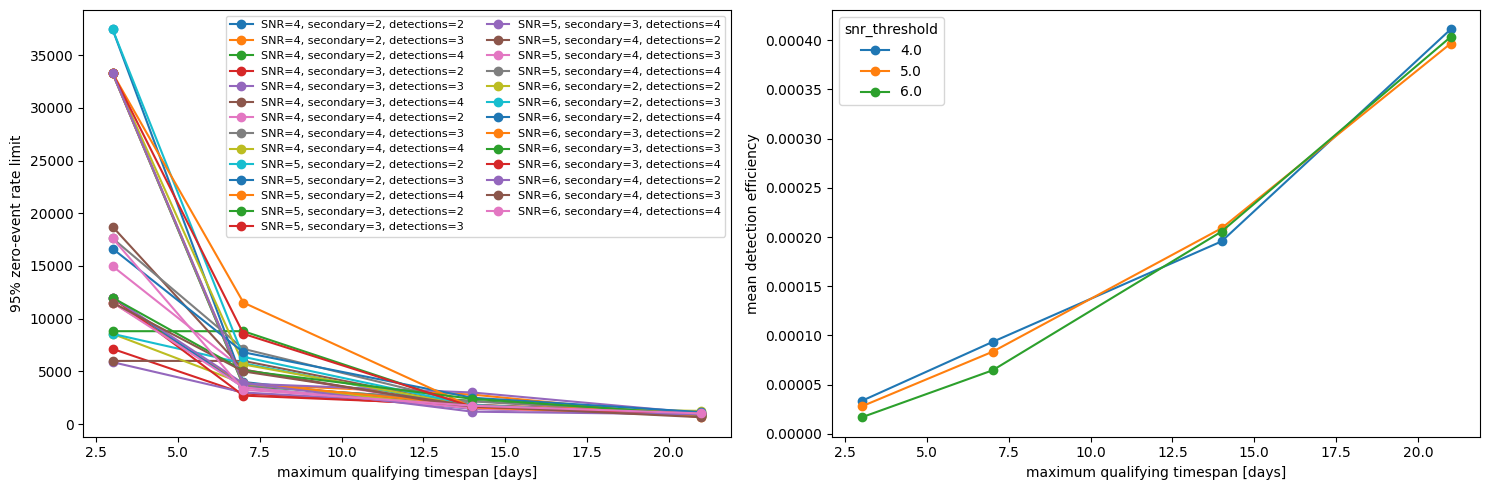

In [7]:
plot_rates = rate_summary[
    (rate_summary['min_detections_primary'] == 1)
    & (rate_summary['min_time_separation_hours'] == 3)
    & (rate_summary['min_fade_rate'] == 0.3)
    & (rate_summary['min_galactic_lat'] == 15)
]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for (snr, secondary, minimum), subset in plot_rates.groupby(
    ['snr_threshold', 'snr_threshold_secondary', 'min_detections']
):
    subset = subset.sort_values('max_timespan_days')
    label = f'SNR={snr:g}, secondary={secondary:g}, detections={int(minimum)}'
    axes[0].plot(subset['max_timespan_days'], subset['rate_95'], marker='o', label=label)
axes[0].set(xlabel='maximum qualifying timespan [days]', ylabel='95% zero-event rate limit')
axes[0].legend(fontsize=8, ncol=2)
pivot = plot_rates.pivot_table(
    index='max_timespan_days', columns='snr_threshold', values='efficiency', aggfunc='mean'
)
pivot.plot(marker='o', ax=axes[1])
axes[1].set(xlabel='maximum qualifying timespan [days]', ylabel='mean detection efficiency')
fig.tight_layout()